# TLM Supervised Fine-Tuning -- Colab (TLM-XS / TLM-S / TLM-M)


# Cell 1 -- Imports & Device

In [11]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import sys, os, re, json, math, random, functools
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/TLM_V03')
assert DRIVE_ROOT.exists(), f"{DRIVE_ROOT} not found -- upload the project to Drive first (see markdown above)"
sys.path.insert(0, str(DRIVE_ROOT))

from src.model_config import ModelConfig, count_parameters
from src.model_variants import TLM_S
from src.tokenizer import TLM_Tokenizer
from src.data_set import make_sft_sr, apply_sr, split_lines_by_newline, join_lines
from src.data_loaders import SFTDataset, collate_sft
from src.training import run_epoch, validate, make_scheduler, compute_loss, compute_loss_label_smoothed, compute_loss_free_pgen
import src.training.training as training  # module itself, for COVERAGE_LAMBDA/PGEN_* overrides below
from src.inference import greedy_decode

import torch
from torch.utils.data import DataLoader
import numpy as np

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}  |  PyTorch: {torch.__version__}")

import gc
for _name in ("model", "optimizer", "scheduler", "_state", "_ckpt", "_best_state"):
    if _name in globals():
        del globals()[_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    print(f"CUDA memory: {torch.cuda.memory_allocated()/1e9:.2f}GB allocated / "
          f"{torch.cuda.memory_reserved()/1e9:.2f}GB reserved")


Mounted at /content/drive
Device: cuda  |  PyTorch: 2.11.0+cu128
CUDA memory: 0.00GB allocated / 0.00GB reserved


## Cell 1b -- Weights & Biases

Was for me to track runs

In [12]:
# %pip install -q wandb
# import wandb
# wandb.login(key="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")


True

## Cell 2 -- Model Variant & Paths


In [ ]:
# -- MODEL VARIANT -- set every run -- must match the bridging checkpoint you're loading
MODEL_VARIANT = "S"   # "XS", "S", or "M" -- see the project spec's model ladder table for the exact
                      # d_model/d_ff/param-count each targets
assert MODEL_VARIANT in ("XXS", "XS", "S", "M"), f"MODEL_VARIANT must be 'XXS', 'XS', 'S' or 'M', got {MODEL_VARIANT!r}"
_variant_prefix = f"tlm_{MODEL_VARIANT.lower()}"

FINETUNE_DIR    = DRIVE_ROOT / "data" / "finetune_data"
FULL_TRAIN_PATH = FINETUNE_DIR / "supervised_finetuning_generated.jsonl"  # full 75k, train_domains

TOKENIZER_PATH = str(DRIVE_ROOT / "src" / "tokenizer" / "tokenizer_tlm_small.json")

# -- VERIFY this before running -- see markdown above --
BRIDGING_CKPT_DIR = DRIVE_ROOT / "data" / "checkpoints" / f"tlm_{MODEL_VARIANT.lower()}_unbiased_copy_bridging"

# This run fine-tunes from the tlm_m_bridging checkpoint that itself bridged
# tlm_m_pretrain_unbiased_copy (compute_loss_free_pgen throughout -- no
# SEARCH/REPLACE role target, "unbiased copy gate", see the bridging
# notebook). BRIDGING_IS_UNBIASED_COPY drives the LOSS_FN
# choice in Cell 3 below -- keep it in sync with whatever BRIDGING_CKPT_DIR
# actually points at.
BRIDGING_IS_UNBIASED_COPY = True

# -- RUN CONFIG -- set every run, see markdown above --
RUN_NAME = f"tlm_{MODEL_VARIANT.lower()}_sft_unbiased_copy"        # e.g. "tlm_s_sft_coverage" for the coverage-penalty experiment; keep variant-scoped
RUN_MODE = "resume"            # "fresh" (from BRIDGING_CKPT_DIR) or "resume" (continue RUN_NAME's own last.pt)
assert RUN_MODE in ("fresh", "resume"), f"RUN_MODE must be 'fresh' or 'resume', got {RUN_MODE!r}"

SFT_CKPT_DIR = DRIVE_ROOT / "data" / "checkpoints" / RUN_NAME
SFT_CKPT_DIR.mkdir(parents=True, exist_ok=True)
print(f"MODEL_VARIANT={MODEL_VARIANT!r}  RUN_NAME={RUN_NAME!r}  RUN_MODE={RUN_MODE!r}  ->  SFT_CKPT_DIR={SFT_CKPT_DIR}")
print(f"  {'OK' if SFT_CKPT_DIR.exists() else 'MISSING'}  {SFT_CKPT_DIR}")


## Cell 2c -- Coverage Penalty Config


In [14]:
COVERAGE_LAMBDA_OVERRIDE = None  # e.g. 1.0, or 0.0 to disable -- None keeps training.py's default

if COVERAGE_LAMBDA_OVERRIDE is not None:
    training.COVERAGE_LAMBDA = COVERAGE_LAMBDA_OVERRIDE
print(f"COVERAGE_LAMBDA = {training.COVERAGE_LAMBDA}")


COVERAGE_LAMBDA = 1.0


## Cell 2b -- Same-domain train/val split

In [15]:
from collections import defaultdict

SFT_TRAIN_PATH = FINETUNE_DIR / "sft_train_domain.jsonl"
SFT_VAL_PATH   = FINETUNE_DIR / "sft_val_domain.jsonl"

_VAL_FRAC   = 0.05
_SPLIT_SEED = 2025

_by_type = defaultdict(list)
with open(FULL_TRAIN_PATH, encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        rec = json.loads(line)
        _by_type[rec["type"]].append(rec)

_rng = random.Random(_SPLIT_SEED)
_train_recs, _val_recs = [], []
for ttype, recs in sorted(_by_type.items()):
    recs = recs[:]
    _rng.shuffle(recs)
    n_val = round(len(recs) * _VAL_FRAC)
    _val_recs.extend(recs[:n_val])
    _train_recs.extend(recs[n_val:])
    print(f"  {ttype:18} total {len(recs):6,}  ->  train {len(recs) - n_val:6,}  val {n_val:4,}")

_rng.shuffle(_train_recs)
_rng.shuffle(_val_recs)

with open(SFT_TRAIN_PATH, "w", encoding="utf-8") as f:
    for rec in _train_recs:
        f.write(json.dumps(rec) + "\n")
with open(SFT_VAL_PATH, "w", encoding="utf-8") as f:
    for rec in _val_recs:
        f.write(json.dumps(rec) + "\n")

print(f"wrote {len(_train_recs):,} -> {SFT_TRAIN_PATH}")
print(f"wrote {len(_val_recs):,} -> {SFT_VAL_PATH}")


  deduplicate        total 15,000  ->  train 14,250  val  750
  extract_method     total 15,000  ->  train 14,250  val  750
  remove_dead_code   total 15,000  ->  train 14,250  val  750
  rename             total 15,000  ->  train 14,250  val  750
  simplify           total 15,000  ->  train 14,250  val  750
wrote 71,250 -> /content/drive/MyDrive/TLM_V03/data/finetune_data/sft_train_domain.jsonl
wrote 3,750 -> /content/drive/MyDrive/TLM_V03/data/finetune_data/sft_val_domain.jsonl


## Cell 3 -- Model Config, Tokenizer & Bridging Checkpoint


In [16]:
if MODEL_VARIANT == "XXS":
    config = ModelConfig(d_model=96, d_ff=384, n_encoder_layers=3, n_decoder_layers=3,
                             n_heads=3, tier_name="TLM_XXS", target_param_count=1_740_000)
elif MODEL_VARIANT == "XS":
    config = ModelConfig(d_model=128, d_ff=512, tier_name="TLM_XS", target_param_count=2_420_000)
elif MODEL_VARIANT == "S":
    config = ModelConfig()
else:  # "M" -- 256 d_model / 1024 d_ff, same 4+4 layers / 4 heads / 6 task types as S
    config = ModelConfig(d_model=256, d_ff=1024, tier_name="TLM_M", target_param_count=9_500_000)
print(config)
print(f"Estimated params: {config.estimated_params()/1e6:.2f}M")

PAD_ID = config.special_token_ids["pad"]

# LABEL_SMOOTHING = 0.1   
# if MODEL_VARIANT == "XS":
#     LOSS_FN = functools.partial(compute_loss_label_smoothed, smoothing=LABEL_SMOOTHING)
#     print(f"Loss: compute_loss_label_smoothed (smoothing={LABEL_SMOOTHING})")
if BRIDGING_IS_UNBIASED_COPY:
    LOSS_FN = compute_loss_free_pgen
    print("Loss: compute_loss_free_pgen")
else:
    # LOSS_FN = compute_loss  # old approach -- role-aware SEARCH/REPLACE target; use when fine-tuning from a role-aware (non-unbiased-copy) bridging checkpoint
    LOSS_FN = compute_loss
    print("Loss: compute_loss (unchanged S/M behavior)")

tokenizer = TLM_Tokenizer(vocab_size=config.vocab_size)
tokenizer.load(TOKENIZER_PATH)
print(f"Tokenizer loaded from {TOKENIZER_PATH}  |  vocab_size = {tokenizer.tokenizer.get_vocab_size()}")

_ckpts = sorted(BRIDGING_CKPT_DIR.glob(f"tlm_{MODEL_VARIANT.lower()}_unbiased_copy_bridging_epoch_*_val*.pt"))
assert _ckpts, (f"No checkpoints found in {BRIDGING_CKPT_DIR} -- fix BRIDGING_CKPT_DIR above "
                 "to point at wherever the bridging Colab run actually saved its checkpoints.")

def _val_loss_from_name(p):
    m = re.search(r"val([0-9.]+)\.pt$", p.name)
    return float(m.group(1)) if m else float("inf")

BRIDGING_CKPT_PATH = min(_ckpts, key=_val_loss_from_name)
print(f"Found {len(_ckpts)} checkpoint(s) in {BRIDGING_CKPT_DIR}")
print(f"Using: {BRIDGING_CKPT_PATH.name}")

model = TLM_S(config)  
_state = torch.load(BRIDGING_CKPT_PATH, map_location=device)
model.load_state_dict(_state["model"])
model.to(device)
print(f"Loaded bridging checkpoint: epoch {_state.get('epoch')}  val_loss {_state.get('val_loss')}  "
      f"val_pgen {_state.get('val_pgen')}")
print(f"Model params: {count_parameters(model)/1e6:.3f}M")


[Config] Estimated params: embed=1920000, enc_attn=589824, dec_attn=1179648, enc_ffn=1183488, dec_ffn=1183488, enc_ln=3456, dec_ln=4992, task_emb=4608, copy_head=193, head=0
ModelConfig [TLM_S]
  d_model=192, n_heads=4
  Encoder: 4L  Decoder: 4L  FFN: 768
  Estimated: 6.07M params  (target: 5.00M)
  Vocab: 10000  MaxSeq: 1024  TaskTypes: 6  WeightTie: True
[Config] Estimated params: embed=1920000, enc_attn=589824, dec_attn=1179648, enc_ffn=1183488, dec_ffn=1183488, enc_ln=3456, dec_ln=4992, task_emb=4608, copy_head=193, head=0
Estimated params: 6.07M
Loss: compute_loss_free_pgen
Tokenizer loaded from /content/drive/MyDrive/TLM_V03/src/tokenizer/tokenizer_tlm_small.json  |  vocab_size = 10000
Found 1 checkpoint(s) in /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_unbiased_copy_bridging
Using: tlm_s_unbiased_copy_bridging_epoch_4_val0.1489.pt
[tlm_s.py] Initialized TLM_S model variant with 6069697 parameters
Loaded bridging checkpoint: epoch 4  val_loss None  val_pgen 0.6967309683

## Cell 4 -- SFT Datasets & DataLoaders


In [17]:
train_ds = SFTDataset(SFT_TRAIN_PATH, tokenizer, config)
val_ds   = SFTDataset(SFT_VAL_PATH, tokenizer, config)
print(f"train: {len(train_ds):,} kept, {train_ds.dropped} dropped {train_ds.dropped_by_type}")
print(f"val:   {len(val_ds):,} kept, {val_ds.dropped} dropped {val_ds.dropped_by_type}")
print(f"train kept by type: {train_ds.kept_by_type}")
print(f"val kept by type:   {val_ds.kept_by_type}")

BATCH_SIZE  = 32
NUM_WORKERS = os.cpu_count() if torch.cuda.is_available() else 0
_PIN        = torch.cuda.is_available()
_collate    = lambda b: collate_sft(b, PAD_ID)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=_collate, num_workers=NUM_WORKERS, pin_memory=_PIN)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=_collate, num_workers=NUM_WORKERS, pin_memory=_PIN)
print(f"train batches: {len(train_loader)}  |  val batches: {len(val_loader)}  |  device: {device}")

_b = next(iter(train_loader))
print("sample batch shapes:", {k: tuple(v.shape) for k, v in _b.items()})
print("sample task_ids:", _b["task_ids"][:8].tolist())


train: 71,192 kept, 58 dropped {'deduplicate': 57, 'rename': 1}
val:   3,747 kept, 3 dropped {'deduplicate': 3}
train kept by type: {'remove_dead_code': 14250, 'simplify': 14250, 'deduplicate': 14193, 'rename': 14249, 'extract_method': 14250}
val kept by type:   {'remove_dead_code': 750, 'rename': 750, 'simplify': 750, 'extract_method': 750, 'deduplicate': 747}
train batches: 2225  |  val batches: 118  |  device: cuda
sample batch shapes: {'enc_ids': (32, 305), 'enc_attn': (32, 305), 'dec_ids': (32, 365), 'task_ids': (32,)}
sample task_ids: [1, 3, 3, 3, 3, 5, 5, 4]


In [18]:
EPOCHS       = 25
LR           = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
GRAD_CLIP    = 1.0
PATIENCE     = 3     

steps_per_epoch = len(train_loader)
total_steps     = steps_per_epoch * EPOCHS
warmup_steps    = int(total_steps * WARMUP_RATIO)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = make_scheduler(optimizer, warmup_steps, total_steps)

print(f"epochs={EPOCHS}  steps/epoch={steps_per_epoch}  total={total_steps}  "
      f"warmup={warmup_steps}  lr={LR}")


epochs=25  steps/epoch=2225  total=55625  warmup=2781  lr=3e-05


## Cell 6 -- Train Loop (resumable)


In [20]:
RESUME_PATH = SFT_CKPT_DIR / "last.pt"
RUN_ID_PATH = SFT_CKPT_DIR / "wandb_run_id.txt"

best_val       = float("inf")
best_ckpt_path = None
bad_epochs     = 0
history        = []
start_epoch    = 1

if RUN_MODE == "resume":
    assert RESUME_PATH.exists(), (
        f"RUN_MODE='resume' but no last.pt found at {RESUME_PATH} -- "
        f"check RUN_NAME={RUN_NAME!r} is correct, or set RUN_MODE='fresh' to start a new run.")
    print(f"Resuming {RUN_NAME!r} from {RESUME_PATH}")
    _ckpt = torch.load(RESUME_PATH, map_location=device)
    model.load_state_dict(_ckpt["model"])
    optimizer.load_state_dict(_ckpt["optimizer"])
    scheduler.load_state_dict(_ckpt["scheduler"])
    start_epoch    = _ckpt["epoch"] + 1
    best_val       = _ckpt["best_val"]
    bad_epochs     = _ckpt["bad_epochs"]
    best_ckpt_path = Path(_ckpt["best_ckpt_path"]) if _ckpt.get("best_ckpt_path") else None
    history        = _ckpt["history"]
    # wandb_run_id   = _ckpt.get("wandb_run_id") or RUN_ID_PATH.read_text().strip()
    print(f"  resuming at epoch {start_epoch}  |  best_val so far {best_val:.4f}  |  "
          f"bad_epochs {bad_epochs}/{PATIENCE}")
    if start_epoch > EPOCHS:
        print("  start_epoch already past EPOCHS -- nothing left to do (bump EPOCHS above to continue).")
else:
    assert not RESUME_PATH.exists(), (
        f"RUN_MODE='fresh' but {RESUME_PATH} already exists (a previous run under "
        f"RUN_NAME={RUN_NAME!r} is in progress) -- set RUN_MODE='resume' to continue it, "
        f"pick a different RUN_NAME for a new experiment, or delete last.pt if you really "
        f"mean to overwrite it.")
    # wandb_run_id = wandb.util.generate_id()
    # RUN_ID_PATH.write_text(wandb_run_id)
    print(f"Starting fresh SFT run {RUN_NAME!r} from bridging checkpoint {BRIDGING_CKPT_PATH.name}")

# wandb is disabled for this run (see Cell 1b -- generate_id AttributeError from a
# stale module cache); wandb_run_id is not tracked while it's off.
# run = wandb.init(
#     project=f"{_variant_prefix}-sft",
#     id=wandb_run_id,
#     resume="allow",
#     config={
#         "run_name": RUN_NAME, "run_mode": RUN_MODE, "model_variant": MODEL_VARIANT,
#         "d_model": config.d_model, "d_ff": config.d_ff, "n_heads": config.n_heads,
#         "n_encoder_layers": config.n_encoder_layers, "n_decoder_layers": config.n_decoder_layers,
#         "lr": LR, "weight_decay": WEIGHT_DECAY, "warmup_ratio": WARMUP_RATIO,
#         "patience": PATIENCE, "grad_clip": GRAD_CLIP, "batch_size": BATCH_SIZE,
#         "epochs": EPOCHS, "init_checkpoint": BRIDGING_CKPT_PATH.name,
#         "coverage_lambda": getattr(training, "COVERAGE_LAMBDA", None),
#         "label_smoothing": LABEL_SMOOTHING if MODEL_VARIANT == "XS" else 0.0,
#         "loss_fn": LOSS_FN.func.__name__ if isinstance(LOSS_FN, functools.partial) else LOSS_FN.__name__,
#     },
# )

for epoch in range(start_epoch, EPOCHS + 1):
    print(f"\n=== Epoch {epoch}/{EPOCHS} ===")
    tr = run_epoch(model, train_loader, optimizer, scheduler, device, PAD_ID,
                   epoch=epoch, sampler=None, ss_enabled=False,
                   grad_clip=GRAD_CLIP, log_every=200, loss_fn=LOSS_FN)
    va = validate(model, val_loader, device, PAD_ID, log_every=40, loss_fn=LOSS_FN)
    print(f"epoch {epoch}: train_loss {tr['loss']:.4f} train_nll {tr['nll_end']:.4f} p_gen {tr['p_gen']:.3f} | "
          f"val_nll {va['nll']:.4f} val_pgen {va['p_gen']:.3f}")
    history.append({"epoch": epoch,
                    "train_loss": tr["loss"], "train_nll": tr["nll_end"], "train_pgen": tr["p_gen"],
                    "val_nll":    va["nll"],  "val_pgen":  va["p_gen"]})

    # wandb.log({
    #     "train/loss": tr["loss"], "train/nll": tr["nll_end"], "train/p_gen": tr["p_gen"],
    #     "val/nll": va["nll"], "val/p_gen": va["p_gen"],
    #     "lr": optimizer.param_groups[0]["lr"],
    # }, step=epoch)

    if va["nll"] < best_val:
        best_val = va["nll"]; bad_epochs = 0
        best_ckpt_path = SFT_CKPT_DIR / f"{RUN_NAME}_epoch_{epoch}_val{va['nll']:.4f}.pt"
        torch.save({"model": model.state_dict(), "epoch": epoch,
                    "val_nll": va["nll"], "val_pgen": va["p_gen"]}, best_ckpt_path)
        print(f"  saved best -> {best_ckpt_path.name}")
    else:
        bad_epochs += 1
        print(f"  no improvement ({bad_epochs}/{PATIENCE})")

    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch,
        "best_val": best_val,
        "bad_epochs": bad_epochs,
        "best_ckpt_path": str(best_ckpt_path) if best_ckpt_path else None,
        "history": history,
    }, RESUME_PATH)

    if bad_epochs >= PATIENCE:
        print("early stopping.")
        break

print(f"\nbest val_nll: {best_val:.4f}")
# wandb.finish() is deferred to the mini-eval cell below, so applied_ok logs to
# this same run instead of a separate one.


Resuming 'tlm_s_sft_unbiased_copy' from /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_sft_unbiased_copy/last.pt
  resuming at epoch 2  |  best_val so far 0.4393  |  bad_epochs 0/3

=== Epoch 2/25 ===
    step     0 | loss 1.0044 | nll 0.5725 | p_gen 0.612 | p_samp 0.00 | lr 2.40e-05
    step   200 | loss 0.8307 | nll 0.4365 | p_gen 0.613 | p_samp 0.00 | lr 2.62e-05
    step   400 | loss 0.8234 | nll 0.4049 | p_gen 0.643 | p_samp 0.00 | lr 2.83e-05
    step   600 | loss 0.7846 | nll 0.4150 | p_gen 0.647 | p_samp 0.00 | lr 3.00e-05
    step   800 | loss 0.9268 | nll 0.5060 | p_gen 0.657 | p_samp 0.00 | lr 3.00e-05
    step  1000 | loss 0.8388 | nll 0.4268 | p_gen 0.645 | p_samp 0.00 | lr 3.00e-05
    step  1200 | loss 0.9155 | nll 0.4935 | p_gen 0.672 | p_samp 0.00 | lr 3.00e-05
    step  1400 | loss 0.7813 | nll 0.4208 | p_gen 0.658 | p_samp 0.00 | lr 3.00e-05
    step  1600 | loss 0.8306 | nll 0.4516 | p_gen 0.647 | p_samp 0.00 | lr 3.00e-05
    step  1800 | loss 0.7760 | nll 0

## Cell 7 -- Training Curves

history saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_sft_unbiased_copy/training_history.json


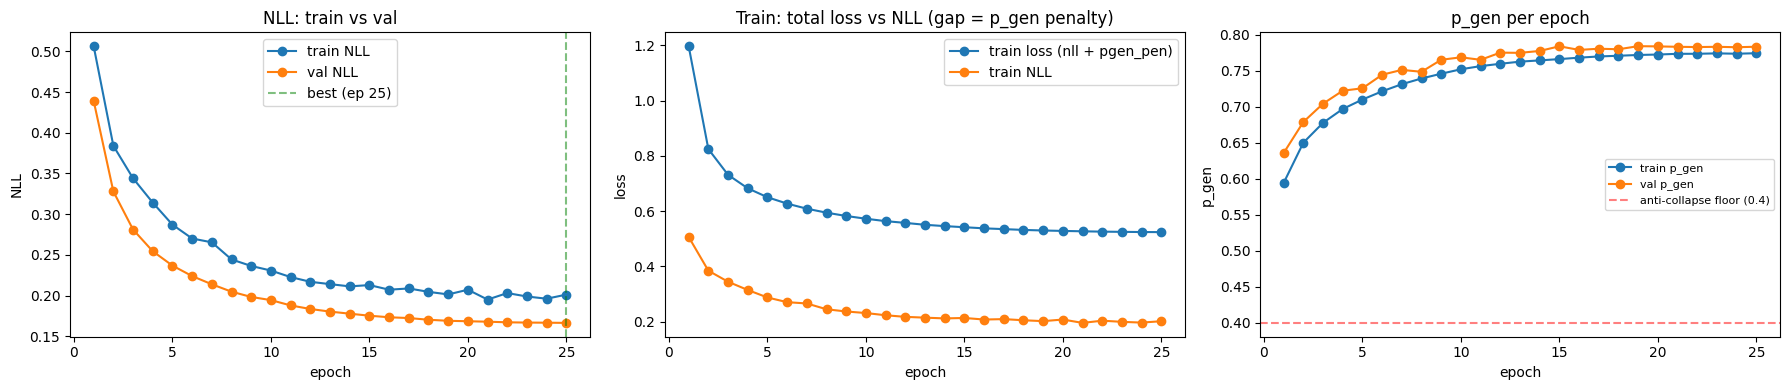

curves saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_sft_unbiased_copy/training_curves.png


In [21]:
import matplotlib.pyplot as plt

history_path = SFT_CKPT_DIR / "training_history.json"
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)
print(f"history saved -> {history_path}")

epochs_x   = [h["epoch"]      for h in history]
train_loss = [h["train_loss"] for h in history]
train_nll  = [h["train_nll"]  for h in history]
val_nll    = [h["val_nll"]    for h in history]
train_pgen = [h["train_pgen"] for h in history]
val_pgen   = [h["val_pgen"]   for h in history]
best_ep    = epochs_x[val_nll.index(min(val_nll))]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

ax1 = axes[0]
ax1.plot(epochs_x, train_nll, marker="o", label="train NLL")
ax1.plot(epochs_x, val_nll,   marker="o", label="val NLL")
ax1.axvline(x=best_ep, color="green", linestyle="--", alpha=0.5, label=f"best (ep {best_ep})")
ax1.set_xlabel("epoch"); ax1.set_ylabel("NLL")
ax1.set_title("NLL: train vs val"); ax1.legend()

ax2 = axes[1]
ax2.plot(epochs_x, train_loss, marker="o", label="train loss (nll + pgen_pen)")
ax2.plot(epochs_x, train_nll,  marker="o", label="train NLL")
ax2.set_xlabel("epoch"); ax2.set_ylabel("loss")
ax2.set_title("Train: total loss vs NLL (gap = p_gen penalty)"); ax2.legend()

ax3 = axes[2]
ax3.plot(epochs_x, train_pgen, marker="o", label="train p_gen")
ax3.plot(epochs_x, val_pgen,   marker="o", label="val p_gen")
if BRIDGING_IS_UNBIASED_COPY:
    # New approach: no SEARCH/REPLACE role target for this run -- only the
    # anti-collapse floor (must match training.py's PGEN_FLOOR).
    ax3.axhline(y=0.4, color="red", linestyle="--", alpha=0.5, label="anti-collapse floor (0.4)")
else:
    # Old approach -- role-aware SR targets, not used for the unbiased-copy run.
    ax3.axhline(y=0.8, color="green", linestyle="--", alpha=0.5, label="SEARCH target (0.8)")
    ax3.axhline(y=0.2, color="gray",  linestyle="--", alpha=0.5, label="REPLACE target (0.2)")
ax3.set_xlabel("epoch"); ax3.set_ylabel("p_gen")
ax3.set_title("p_gen per epoch"); ax3.legend(fontsize=8)

plt.tight_layout()
plot_path = SFT_CKPT_DIR / "training_curves.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"curves saved -> {plot_path}")
